In [66]:
import pandas as pd
from sklearn.model_selection import GridSearchCV
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, classification_report
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
import xgboost as xgb
from sklearn.metrics import *
from sklearn.preprocessing import *

In [29]:
Cdata = pd.read_csv("/content/sample_data/combined_partner_churn_data.csv")
Cdata.head()

,partner_id,partner_tier,is_churned,login_frequency_baseline,login_rolling_avg_7d,login_rolling_avg_30d,login_decline_7d,login_decline_30d,login_decline_ratio,login_acceleration,...,tier_program_engagement,api_integration_status,ticket_count_increase_30d,ticket_sentiment_trend,avg_response_time_to_outreach,outreach_ignored_count,competitor_mention_flag,pricing_complaint_flag,commission_rate_inquiry_count,feature_request_intensity
0,P0001,Silver,1,17,0.65,8.42,-0.333,-0.623,0.495,-0.0778,...,1,1,0,0.665,12.76,1,0,0,0,0
1,P0002,Bronze,1,5,0.28,2.72,-0.366,-0.207,0.544,-0.0925,...,0,1,1,0.289,4.00,1,0,0,0,0
2,P0003,Bronze,0,9,2.36,11.89,-0.012,-0.038,1.321,0.0484,...,0,2,0,0.194,11.58,0,0,0,0,0
3,P0004,Gold,0,19,4.33,21.55,-0.077,-0.112,1.134,-0.0440,...,0,0,0,-0.144,4.38,1,0,0,1,0
4,P0005,Silver,0,12,3.15,13.29,-0.060,-0.108,1.107,0.0127,...,1,0,1,-0.225,7.19,0,0,0,0,0


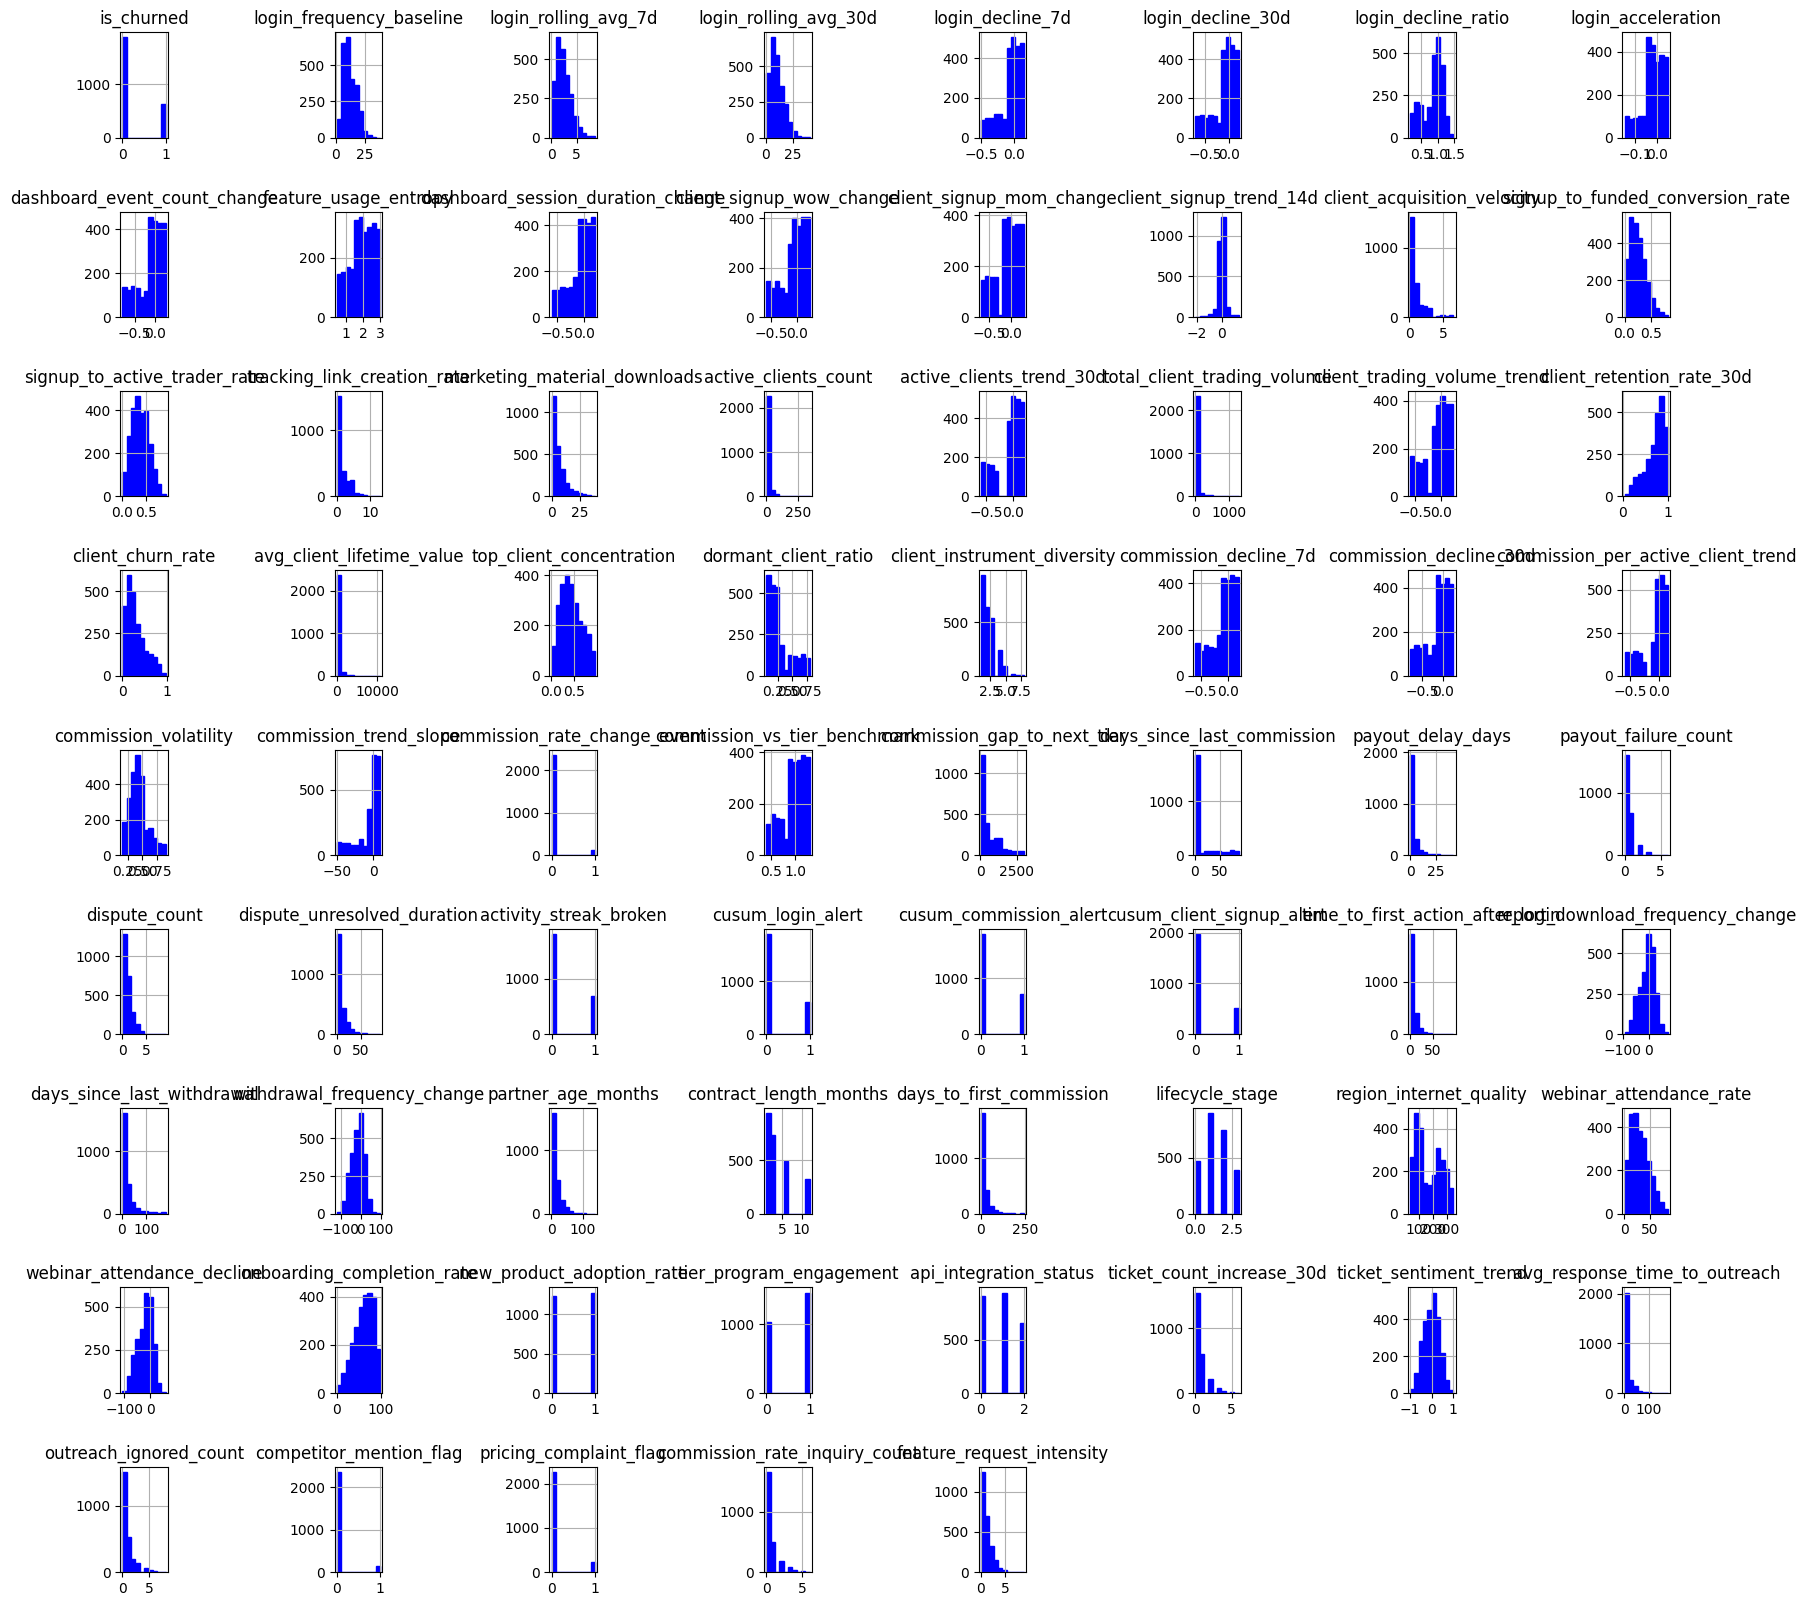

In [30]:
Cdata.hist(figsize=(20,20), edgecolor="blue", color="blue")
plt.subplots_adjust(hspace=0.7, wspace=3.5)
plt.show()

In [31]:
print("Shape:", Cdata.shape)


Shape: (2500, 74)


In [32]:
Cdata.isnull().sum()

,0
partner_id,0
partner_tier,0
is_churned,0
login_frequency_baseline,0
login_rolling_avg_7d,0
...,...
outreach_ignored_count,0
competitor_mention_flag,0
pricing_complaint_flag,0
commission_rate_inquiry_count,0


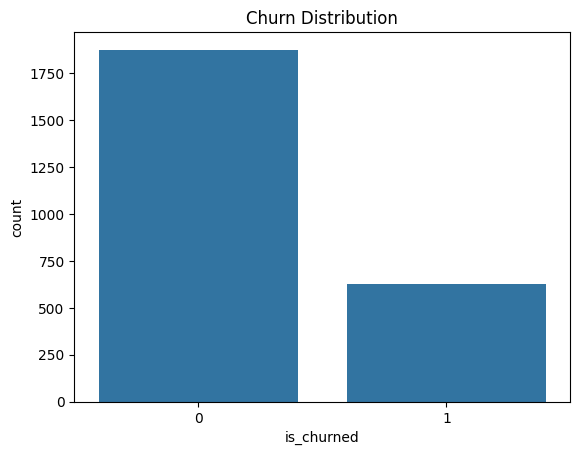

is_churned
0    0.75
1    0.25
Name: proportion, dtype: float64


In [42]:
sns.countplot(x="is_churned", data = Cdata)
plt.title("Churn Distribution")
plt.show()

print(Cdata["is_churned"].value_counts(normalize=True))

In [46]:
categorical_cols = Cdata.select_dtypes(include="object").columns

le = LabelEncoder()

for col in categorical_cols:
    Cdata[col] = le.fit_transform(Cdata[col])

In [50]:
X = Cdata.drop("is_churned", axis=1)
y = Cdata["is_churned"]

In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [57]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [102]:
# turning
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear']  # Good for smaller datasets
}

# Class Weighting
lr_tuned = GridSearchCV(
    estimator=LogisticRegression(class_weight='balanced', max_iter=2000, random_state=2020),
    param_grid=param_grid_lr,
    cv=3,
    scoring='roc_auc'
)


lr_tuned.fit(X_train_scaled, y_train)

# et Best Model
best_lr = lr_tuned.best_estimator_

# Predictions
lr_pred = best_lr.predict(X_test_scaled)
lr_prob = best_lr.predict_proba(X_test_scaled)[:, 1]

# Evaluating
lr_acc = accuracy_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)
lr_auc = roc_auc_score(y_test, lr_prob)

print(f"Best LR Params: {lr_tuned.best_params_}")
print(f"Logistic Regression Recall: {lr_recall:.4f}")
print(f"Logistic Regression AUC: {lr_auc:.4f}")



Best LR Params: {'C': 0.01, 'solver': 'liblinear'}
Logistic Regression Recall: 1.0000
Logistic Regression AUC: 1.0000


In [101]:
y_pred_log = best_lr.predict(X_test_scaled)

print("Logistic Regression Results")
print(classification_report(y_test, y_pred_log))
print("ROC-AUC:", roc_auc_score(y_test, best_log.predict_proba(X_test_scaled)[:,1]))


Logistic Regression Results
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       375
           1       1.00      1.00      1.00       125

    accuracy                           1.00       500
   macro avg       1.00      1.00      1.00       500
weighted avg       1.00      1.00      1.00       500

ROC-AUC: 1.0


In [86]:
xgb_model = xgb.XGBClassifier(eval_metric='logloss')

param_grid_xgb = {
    'n_estimators': [100, 200],
    'max_depth': [5, 7],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.8, 1]
}

grid_xgb = GridSearchCV(xgb_model, param_grid_xgb, cv=5, scoring='roc_auc')
grid_xgb.fit(X_train, y_train)

best_xgb = grid_xgb.best_estimator_


In [88]:
y_pred_xgb = best_xgb.predict(X_test)

print("XGBoost Results")
print(classification_report(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, best_xgb.predict_proba(X_test)[:,1]))


XGBoost Results
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       375
           1       0.99      1.00      1.00       125

    accuracy                           1.00       500
   macro avg       1.00      1.00      1.00       500
weighted avg       1.00      1.00      1.00       500

ROC-AUC: 1.0


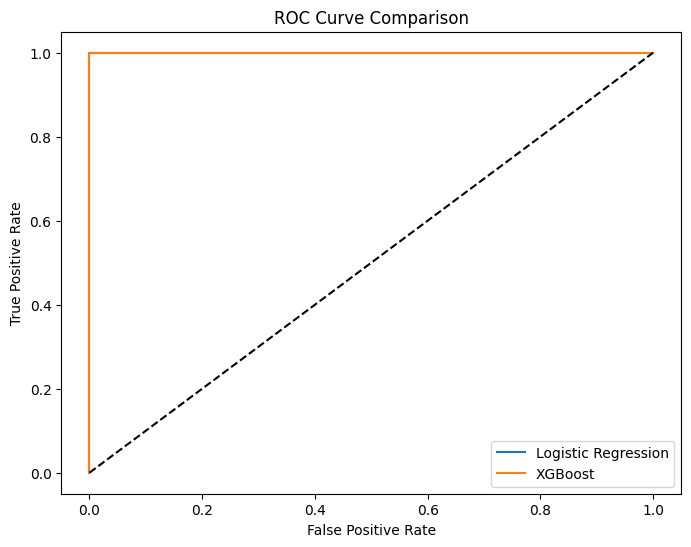

In [72]:
log_probs = best_log.predict_proba(X_test_scaled)[:,1]
xgb_probs = best_xgb.predict_proba(X_test)[:,1]

fpr_log, tpr_log, _ = roc_curve(y_test, log_probs)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_probs)

plt.figure(figsize=(8,6))
plt.plot(fpr_log, tpr_log, label="Logistic Regression")
plt.plot(fpr_xgb, tpr_xgb, label="XGBoost")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()


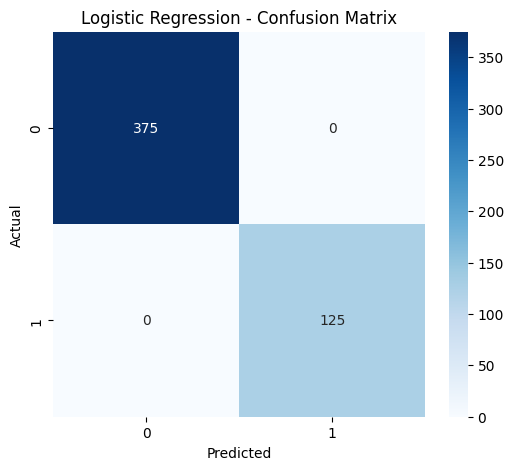

In [81]:
cm_log = confusion_matrix(y_test, y_pred_log)
plt.figure(figsize=(6,5))
sns.heatmap(cm_log, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

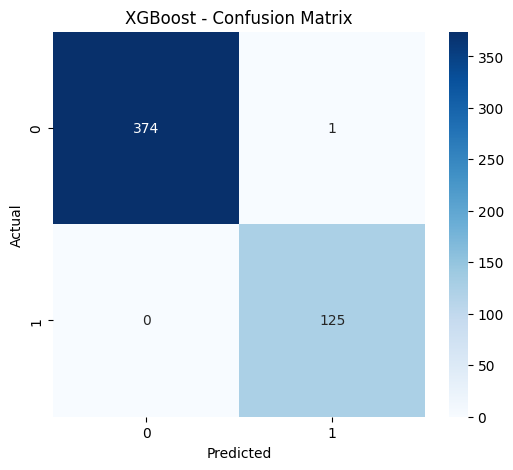

In [85]:

cm_xgb = confusion_matrix(y_test, y_pred_xgb)
plt.figure(figsize=(6,5))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost - Confusion Matrix")
plt.show()
